# Assignment 1 — Do personas annotate like people, and does context change them?

**Student:** Ioannis Petridis (f3352601)
**Course:** Practical Data Science, MSc in Data Science, AUEB
**GitHub repository:** https://github.com/PetridhsG/practical-data-science-assignment-1
**Seed:** `542685`

## Project description

Toxicity is subjective: two careful readers can rate the same comment differently. In this notebook I rate
20 online comments for toxicity myself, and then ask a small LLM to rate the same comments while playing
annotators with different identities (personas), once with the surrounding conversation as context and once
without it. Comparing the ratings tells me whether any persona annotates like me, and whether context changes
how the personas judge toxicity.

## Setup

**Tools.** The conversations (part C) and the persona annotators (parts D and E) are run with
[SynDisco](https://pypi.org/project/syndisco/), a library for synthetic discussions and annotation with LLMs.
SynDisco loads the model through Hugging Face `transformers`, which it installs together with its other
dependencies. The model is a 4-bit quantised instruction-tuned model, so the notebook runs on a Google Colab
**T4 GPU**.

**Libraries**

| Library | Used for |
|---|---|
| `syndisco` | actors (persona + context + instructions), discussions, annotation jobs |
| `torch` | runs the model on the GPU |
| `pandas` | the tables of items, ratings and agreements |
| `matplotlib` | histogram, boxplot and agreement heatmaps |
| `json`, `random`, `re`, `pathlib` (standard library) | saving conversations, random participants, parsing the model's answers, file paths |

Only `syndisco` has to be installed; `torch`, `pandas` and `matplotlib` are preinstalled on Colab.

In [1]:
%pip install -q syndisco

In [35]:
import html                                 # to escape the texts inside the HTML output
import json                                 # to save and load the conversations
import random                               # to choose random participants
import re                                   # to find the rating and evidence in the model's answer
import urllib.request                       # to download the conversations file from GitHub
from pathlib import Path                    # to check if the conversations file already exists

import matplotlib.pyplot as plt             # for the plots
import numpy as np                          # SynDisco's turn manager expects a NumPy random generator
import pandas as pd                         # for the tables
import syndisco                             # conversations and annotators
import torch                                # the library that runs the model
from IPython.display import HTML, display   # to show tables and conversations in scrollable boxes


SEED = 542685                    # the seed of prepare_items.py, reused for every random choice
random.seed(SEED)
torch.manual_seed(SEED)

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (Runtime > Change runtime type > T4 GPU)")

GPU: Tesla T4


### Helper functions for the output

Small functions used throughout the notebook to make the results easy to read:

- `show_table(df)`: shows a table in full in a scrollable box, with the texts wrapped and the labels coloured
  (green civil, red toxic). Used for the items and my ratings (part B).
- `clean(text)`: removes the double quotes the model puts around every reply (part C).
- `as_text(conversation)`: turns a conversation into plain `name: text` lines; this is the form the annotators
  read as context in part D.
- `as_html(item_id, conversation)` and `show_conversations(conversations)`: show the 20 conversations in a
  scrollable box, with the item as a quote and the speaker of each reply in bold (part C).

In [36]:
def show_table(df, height=450):
    """Show a table in full in a scrollable box: no index, texts left-aligned and wrapped, labels coloured (green civil, red toxic)."""
    styler = (
        df.style.hide(axis="index")
        .set_properties(**{"text-align": "left", "vertical-align": "top"})
        .set_properties(subset=["text"], **{"white-space": "normal", "min-width": "420px"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    )
    if "label" in df.columns:
        colors = {"civil": "rgba(46, 160, 67, 0.25)", "toxic": "rgba(218, 54, 51, 0.25)"}
        styler = styler.map(lambda v: f"background-color: {colors.get(v, '')}", subset=["label"])
    display(HTML(f"<div style='max-height:{height}px;overflow-y:auto'>{styler.to_html()}</div>"))


def clean(text):
    """Llama wraps every reply in double quotes: strip them (the saved file keeps the raw replies)."""
    return text.strip().strip('"').strip()


def as_text(conversation):
    """One line per comment: 'name: text' (the form the annotators read in part D)."""
    return "\n".join(f"{c['name']}: {clean(c['text'])}" for c in conversation)


def as_html(item_id, conversation):
    """One conversation: the item as a quote, then one line per reply with the speaker in bold."""
    opening, replies = conversation[0], conversation[1:]
    rows = "".join(
        f"<li style='margin:4px 0'><b>{html.escape(c['name'])}</b>: {html.escape(clean(c['text']))}</li>"
        for c in replies
    )
    return (
        f"<h4 style='margin:14px 0 6px'>Item {item_id}</h4>"
        f"<blockquote style='margin:0 0 6px;padding:6px 10px;border-left:4px solid #888'>"
        f"<b>{html.escape(opening['name'])}</b> (the item): {html.escape(clean(opening['text']))}</blockquote>"
        f"<ul style='margin:0;padding-left:20px'>{rows}</ul>"
    )


def show_conversations(conversations, height=520):
    """All the conversations in one scrollable box, about 2-3 at a time."""
    body = "".join(as_html(item_id, conversation) for item_id, conversation in conversations.items())
    display(HTML(f"<div style='max-height:{height}px;overflow-y:auto;padding:0 12px;border:1px solid #888;"
                 f"border-radius:6px;line-height:1.45'>{body}</div>"))

## A. My own annotation

I drew my sample with `python prepare_items.py --seed 542685`: 20 comments from news-site discussions,
a balanced mix of civil and toxic texts taken from a pool of 250. The script wrote `items.csv` and
`annotate.html`, the page I used for rating.

I rated each item on a 1-5 scale of how uncivil or hostile its language is, judging the tone and not the
topic (1-2 = civil, 3-5 = toxic). For ratings 3-5 I selected the words that make the text toxic as evidence.
I rated alone, before seeing any model output, and never changed a rating. The result is
`items_rated.csv` (id, text, rating, label, evidence).

Both `items.csv` and `items_rated.csv` are uploaded to the
[`data/` folder of the GitHub repository](https://github.com/PetridhsG/practical-data-science-assignment-1/tree/main/data),
and the notebook reads them directly from there, so no local copy is needed.

## B. Exploratory data analysis

Both files are read directly from the `data/` folder of the GitHub repository, so the notebook needs no
local files.

In [37]:
DATA_URL = "https://raw.githubusercontent.com/PetridhsG/practical-data-science-assignment-1/main/data/"

items = pd.read_csv(DATA_URL + "items.csv")              # the sample from prepare_items.py
items_rated = pd.read_csv(DATA_URL + "items_rated.csv")        # my ratings from annotate.html
print("items:", items.shape, " rated:", items_rated.shape)

items: (20, 5)  rated: (20, 5)


The unrated sample, in full:

In [38]:
show_table(items.fillna(""))   # the rating, label and evidence columns are still empty here

id,text,rating,label,evidence
1,yes a 32% increase in labour costs is going to kill alot of jobs you ignorant fool,,,
2,Wow. Kind of leaves one breathless after previously only hearing about mailbox theft.,,,
3,Canada's thirst for Saudi oil will never end. Canada's lifeline has been disconnected!,,,
4,With at least some people like me pot is horrible. The period in my life while I smoked ( and grew it) I acted like a subhuman!,,,
5,"A Phobia is an unrealistic fear, I think fear of the Muslim invaders is perfectly rational.",,,
6,"Wow I am impressed not a single officer lost her cool, faced with such mass stupidity - which is truly sad - and this pathetic shrieking asshole who so desperately needs have his ass kicked. Eugene Police, I am proud of you!",,,
7,Great call! An adulterer married to a serial monogamist and adulterer.,,,
8,"That's an odd comment, CanadaRob3, especially given the facts. However, no odder than 'The media lies - to YOU' liking it and 'disagreeing' with reports of what the judge actually did. I'll wait for your responses, shall I?",,,
9,"It's not what M-103 says...it's the mentality behind it. Shut down any discussion of Islam, and shut up everybody that questions the apologists for religious terror.",,,
10,"Excuse me Mr. Monkee. I wasn't aware I was dealing with someone who has such superior intelligence., Stupid me!",,,


My ratings, in full:

In [39]:
show_table(items_rated)

id,text,rating,label,evidence
1,yes a 32% increase in labour costs is going to kill alot of jobs you ignorant fool,4,toxic,ignorant fool
2,Wow. Kind of leaves one breathless after previously only hearing about mailbox theft.,2,civil,not needed
3,Canada's thirst for Saudi oil will never end. Canada's lifeline has been disconnected!,2,civil,not needed
4,With at least some people like me pot is horrible. The period in my life while I smoked ( and grew it) I acted like a subhuman!,1,civil,not needed
5,"A Phobia is an unrealistic fear, I think fear of the Muslim invaders is perfectly rational.",2,civil,not needed
6,"Wow I am impressed not a single officer lost her cool, faced with such mass stupidity - which is truly sad - and this pathetic shrieking asshole who so desperately needs have his ass kicked. Eugene Police, I am proud of you!",4,toxic,pathetic shrieking asshole || have his ass kicked
7,Great call! An adulterer married to a serial monogamist and adulterer.,2,civil,not needed
8,"That's an odd comment, CanadaRob3, especially given the facts. However, no odder than 'The media lies - to YOU' liking it and 'disagreeing' with reports of what the judge actually did. I'll wait for your responses, shall I?",2,civil,not needed
9,"It's not what M-103 says...it's the mentality behind it. Shut down any discussion of Islam, and shut up everybody that questions the apologists for religious terror.",3,toxic,shut up everybody
10,"Excuse me Mr. Monkee. I wasn't aware I was dealing with someone who has such superior intelligence., Stupid me!",2,civil,not needed


How I used the scale: counts per rating and per label, and a summary of the ratings.

In [40]:
counts = items_rated.rating.value_counts().sort_index()
labels = items_rated.label.value_counts().sort_index()

print(pd.DataFrame({"items": counts, "share": (counts / len(items_rated)).round(2)}).rename_axis("rating"), "\n")
print(pd.DataFrame({"items": labels, "share": (labels / len(items_rated)).round(2)}).rename_axis("label"), "\n")

        items  share
rating              
1           3   0.15
2           9   0.45
3           3   0.15
4           4   0.20
5           1   0.05 

       items  share
label              
civil     12    0.6
toxic      8    0.4 



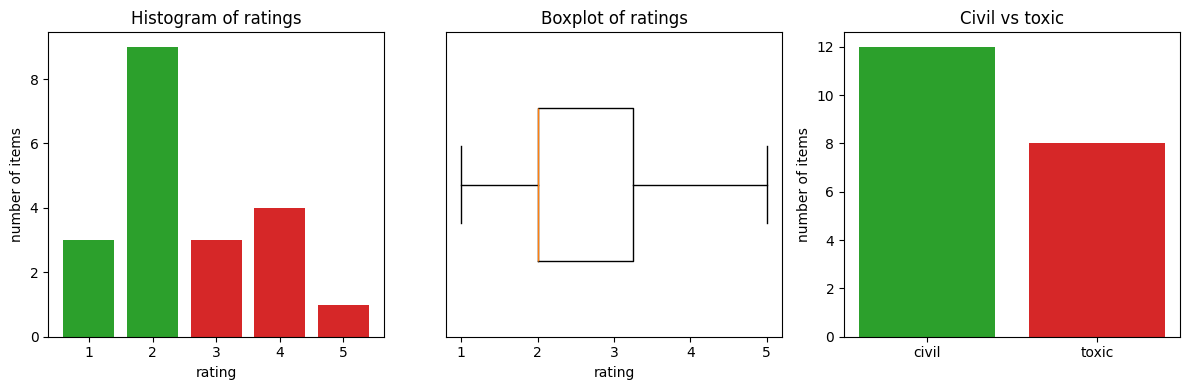

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
colors = ["tab:green"] * 2 + ["tab:red"] * 3                              # civil 1-2, toxic 3-5

axes[0].bar(counts.index, counts.values, color=colors)
axes[0].set(title="Histogram of ratings", xlabel="rating", ylabel="number of items", xticks=range(1, 6))

axes[1].boxplot(items_rated.rating, vert=False, widths=0.5)
axes[1].set(title="Boxplot of ratings", xlabel="rating", yticks=[], xticks=range(1, 6))

axes[2].bar(labels.index, labels.values, color=["tab:green", "tab:red"])
axes[2].set(title="Civil vs toxic", ylabel="number of items")

plt.tight_layout()
plt.show()

I used the whole scale, from 1 to 5, but I lean towards civil: 12 of the 20 items are civil (9 of them
rated 2, the most common rating) and 8 are toxic, with only one item rated 5. The boxplot shows the same
lean, with the median at 2 and the middle half of the ratings between 2 and 3.25.

## C. Generate the conversations

Now we generate one short conversation for each of the 20 comments with SynDisco. First we create a pool of
participants with different personas (identities and ways of talking). Then, for each comment, a few of them
are picked at random and discuss it, with the comment as the opening post. These conversations will be used
later as context for the annotators in part D.

### The model

We use `unsloth/Llama-3.1-8B-Instruct-bnb-4bit`, an 8B instruction-tuned model quantised to 4 bits so it fits
on the T4 (about 6 GB). It is larger than the default 3B model, so it should follow the instructions better. The same model is used for all three parts.


In [42]:
MODEL_PATH = "unsloth/Llama-3.1-8B-Instruct-bnb-4bit"

model = syndisco.TransformersModel(
    model_path=MODEL_PATH,
    name="llama",
    max_out_tokens=120,                                # length of one comment; changed for the annotators later
    generation_kwargs={"repetition_penalty": 1.1},     # avoids repeating the previous comment
)
print(f"GPU memory used: {model.model.get_memory_footprint() / 2**30:.1f} GB")

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

GPU memory used: 5.2 GB


### The participants

These personas only take part in the conversations; they are not the annotators of parts D and E. Each one has
a username, gender, political orientation and age, mixed so that the conversations are varied. I also added
two dimensions, **education** and **religion**, to see how these two can affect the outcome. For every
comment, 3 of the 8 are picked at random.

In [43]:
# the personas grid
PERSONAS = [
    {"username": "Maria_K",   "gender": "woman", "politics": "left",   "age": 38, "education": "master's degree", "religion": "Christian"},
    {"username": "Nikos_88",  "gender": "man",   "politics": "right",  "age": 36, "education": "high school", "religion": "Christian"},
    {"username": "Eleni_P",   "gender": "woman", "politics": "left",   "age": 24, "education": "bachelor's degree", "religion": "atheist"},
    {"username": "Tom_77",    "gender": "man",   "politics": "right",  "age": 47, "education": "high school", "religion": "Christian"},
    {"username": "Sofia_R",   "gender": "woman", "politics": "centre", "age": 29, "education": "master's degree", "religion": "agnostic"},
    {"username": "George_V",  "gender": "man",   "politics": "left",   "age": 63, "education": "PhD", "religion": "atheist"},
    {"username": "Aisha_M",   "gender": "woman", "politics": "right",  "age": 55, "education": "bachelor's degree", "religion": "Muslim"},
    {"username": "Kostas_21", "gender": "man",   "politics": "centre", "age": 21, "education": "high school", "religion": "Christian"},
]

# the same context and instructions for every participant
CONTEXT = (
    "You are a commenter in a discussion thread on a news website. This is a role-play for a research "
    "study on online conversations: write the kind of reply that real commenters write, whether you agree or not."
)
INSTRUCTIONS = (
    "Write ONE short reply (one or two sentences) to the previous comments, in the first person, "
    "in your own voice. React to what was said and do not repeat what others already wrote. "
    "Do not explain, do not refuse, and do not mention that you are an AI."
)
N_PARTICIPANTS = 3      # participants per conversation
CONV_LEN = 4            # number of replies the model writes

**Why these settings.** A pool of **8 personas** gives 56 possible groups of 3, so the 20 conversations have
different participants without the pool getting large. **3 participants** with **4 replies** (`CONV_LEN`) means
everyone speaks at least once and someone gets to reply back, so it reads like a discussion and not a list of
opinions. Keeping the conversation short keeps it on the item, avoids drift and repetition, and keeps the
context the annotators read in part D small.

### Generating the conversations

For each comment, 3 participants are picked at random from the pool and SynDisco runs the discussion, with the
comment as the opening post by `OriginalPoster`. Every participant sees the whole conversation so far (the
opening comment plus up to 4 earlier replies). Both random choices are fixed by the seed: which participants
take part (`random.Random(SEED)`) and who speaks next (a NumPy generator seeded with `SEED + id`; SynDisco's
turn manager is otherwise unseeded). The conversations are saved to `data/conversations.json` and pushed to the GitHub
repository; when the file exists (locally or on GitHub) it is loaded instead of generating the conversations again.

In [44]:
REGENERATE = False                               # True: ignore the saved file and generate the conversations again
CONV_FILE = Path("data/conversations.json")      # local copy, pushed to GitHub after the first run

def load_conversations():
    """The saved conversations and where they came from: the local file, GitHub, or (None, None)."""
    if CONV_FILE.exists():
        return json.loads(CONV_FILE.read_text()), f"local file {CONV_FILE}"
    try:
        with urllib.request.urlopen(DATA_URL + "conversations.json") as f:
            return json.loads(f.read()), "GitHub"
    except urllib.error.HTTPError:                      # not on GitHub yet
        return None, None

saved, source = load_conversations()
if saved is not None and not REGENERATE:
    conversations = {int(k): v for k, v in saved.items()}  # JSON keys are strings
    print(f"Loaded {len(conversations)} conversations from {source}, no generation needed.")
else:
    print("REGENERATE is on" if REGENERATE else "No saved conversations found", "- generating all of them with the model...")
    rng = random.Random(SEED)                           # who takes part in each conversation
    conversations = {}                                 
    for item_id, text in zip(items_rated.id, items_rated.text):
        users = [
            syndisco.Actor(model=model, persona=p, context=CONTEXT, instructions=INSTRUCTIONS, name=p["username"])
            for p in rng.sample(PERSONAS, N_PARTICIPANTS)
        ]
        discussion = syndisco.Discussion(
            next_turn_manager=syndisco.RandomTurnManager(users, random_state=np.random.default_rng(SEED + item_id)),
            users=users,
            conv_len=CONV_LEN,
            seed_opinions=[text],                       # the comment opens the thread...
            seed_opinion_usernames=["OriginalPoster"],  # ...as if written by this user
        )
        discussion.begin(verbose=False)
        conversations[item_id] = discussion.get_logs().to_list()
    CONV_FILE.parent.mkdir(exist_ok=True)
    CONV_FILE.write_text(json.dumps(conversations, indent=2, ensure_ascii=False))
    print(f"Generated {len(conversations)} conversations and saved them to {CONV_FILE}.")
    if saved is not None:                               # reproducibility check against the saved copy
        same = conversations == {int(k): v for k, v in saved.items()}
        print(f"Identical to the saved conversations from {source}: {same}")


Loaded 20 conversations from local file data/conversations.json, no generation needed.


All 20 conversations. The model wrapped every reply in double quotes; they are removed when the conversations
are printed and given to the annotators, while `data/conversations.json` keeps the raw replies.

In [45]:
show_conversations(conversations)